In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')

df = pd.read_csv('/content/india_inflation_dataset.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset Shape: (448, 21)


,Record_ID,Observation_Date,Year,Quarter,State,Region,Sector,CPI_Index_Base2012,Headline_Inflation_YoY_Pct,Food_Inflation_YoY_Pct,...,Housing_Inflation_YoY_Pct,Healthcare_Inflation_YoY_Pct,RBI_Repo_Rate_Pct,Rice_Price_INR_Kg,Toor_Dal_Price_INR_Kg,Milk_Price_INR_Litre,Petrol_Price_INR_Litre,LPG_Cylinder_INR,Purchasing_Power_of_1000_INR,RBI_Band_Status
0,1001,2019-01-01,2019,Q1,Tamil Nadu,South,Urban,139.7,4.26,3.27,...,5.14,5.76,6.25,33.51,80.33,44.79,72.37,707.65,1002.15,Within Comfort Zone (4%-6%)
1,1002,2019-01-01,2019,Q1,Tamil Nadu,South,Rural,139.7,4.03,3.79,...,3.36,5.37,6.25,32.17,77.35,43.72,70.59,711.57,1002.15,Within Comfort Zone (4%-6%)
2,1003,2019-01-01,2019,Q1,Maharashtra,West,Urban,140.2,4.00,2.94,...,5.54,5.23,6.25,34.20,77.95,43.73,72.31,704.25,998.57,Within Comfort Zone (4%-6%)
3,1004,2019-01-01,2019,Q1,Maharashtra,West,Rural,140.2,4.10,4.02,...,3.56,5.12,6.25,35.63,80.77,43.47,73.02,703.90,998.57,Within Comfort Zone (4%-6%)
4,1005,2019-01-01,2019,Q1,Karnataka,South,Urban,140.0,4.00,3.34,...,4.65,5.36,6.25,34.59,81.14,43.94,71.70,702.61,1000.00,Within Comfort Zone (4%-6%)


In [ ]:
df_clean = df.copy()
df_clean['Observation_Date'] = pd.to_datetime(df_clean['Observation_Date'])

# Check and remove duplicates
print("Duplicate rows:", df_clean.duplicated(subset=['Year', 'Quarter', 'State', 'Sector']).sum())
df_clean = df_clean.drop_duplicates(subset=['Year', 'Quarter', 'State', 'Sector'])

# Impute missing numeric values if any using State-Sector median
numeric_cols = df_clean.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean.groupby(['State', 'Sector'])[col].transform(lambda x: x.fillna(x.median()))

df_clean = df_clean.sort_values(by=['State', 'Sector', 'Observation_Date']).reset_index(drop=True)
print("Data cleaned successfully!")


Duplicate rows: 0
Data cleaned successfully!


In [ ]:
df_feat = df_clean.copy()

# 1. Real Interest Rate (%) = RBI Repo Rate - Headline Inflation
df_feat['Real_Interest_Rate_Pct'] = (df_feat['RBI_Repo_Rate_Pct'] - df_feat['Headline_Inflation_YoY_Pct']).round(2)

# 2. Monthly Household Essential Basket (10kg Rice + 3kg Toor Dal + 15L Milk + 1 LPG Cylinder)
df_feat['Monthly_Essential_Basket_INR'] = (
    10 * df_feat['Rice_Price_INR_Kg'] +
    3 * df_feat['Toor_Dal_Price_INR_Kg'] +
    15 * df_feat['Milk_Price_INR_Litre'] +
    1 * df_feat['LPG_Cylinder_INR']
).round(2)

# 3. Purchasing Power Loss (%) relative to Rs. 1,000 in 2019
df_feat['Purchasing_Power_Loss_Pct'] = (((1000.0 - df_feat['Purchasing_Power_of_1000_INR']) / 1000.0) * 100).round(2)

# 4. Quarter-over-Quarter (QoQ) Inflation Change
df_feat['QoQ_Inflation_Delta'] = df_feat.groupby(['State', 'Sector'])['Headline_Inflation_YoY_Pct'].diff().fillna(0.0).round(2)

# 5. RBI Upper Tolerance (>6%) Breach Flag
df_feat['RBI_Breach_Flag'] = np.where(df_feat['Headline_Inflation_YoY_Pct'] > 6.0, 1, 0)

display(df_feat[['Year', 'Quarter', 'State', 'Sector', 'Real_Interest_Rate_Pct', 'Monthly_Essential_Basket_INR', 'Purchasing_Power_Loss_Pct', 'RBI_Breach_Flag']].head(10))


,Year,Quarter,State,Sector,Real_Interest_Rate_Pct,Monthly_Essential_Basket_INR,Purchasing_Power_Loss_Pct,RBI_Breach_Flag
0,2019,Q1,Delhi,Rural,1.98,1951.62,-0.21,0
1,2019,Q2,Delhi,Rural,1.44,1981.81,0.71,0
2,2019,Q3,Delhi,Rural,0.49,2024.01,1.82,0
3,2019,Q4,Delhi,Rural,1.24,2065.08,2.24,0
4,2020,Q1,Delhi,Rural,-1.44,2103.31,4.50,0
5,2020,Q2,Delhi,Rural,-1.96,2138.07,5.79,0
6,2020,Q3,Delhi,Rural,-2.84,2184.23,7.95,1
7,2020,Q4,Delhi,Rural,-2.07,2186.91,8.26,1
8,2021,Q1,Delhi,Rural,-1.51,2262.08,8.56,0
9,2021,Q2,Delhi,Rural,-2.00,2294.16,10.43,0


In [ ]:
print("=== 1. Annual Macroeconomic & Purchasing Power Trend (2019-2025) ===")
annual_summary = df_feat.groupby('Year').agg(
    Avg_Headline_CPI=('Headline_Inflation_YoY_Pct', 'mean'),
    Avg_Food_Inflation=('Food_Inflation_YoY_Pct', 'mean'),
    Avg_Fuel_Inflation=('Fuel_Inflation_YoY_Pct', 'mean'),
    Avg_Repo_Rate=('RBI_Repo_Rate_Pct', 'mean'),
    Avg_Purchasing_Power_of_1000=('Purchasing_Power_of_1000_INR', 'mean'),
    Avg_Essential_Basket_INR=('Monthly_Essential_Basket_INR', 'mean'),
    RBI_Breach_Rate_Pct=('RBI_Breach_Flag', lambda x: round(x.mean() * 100, 1))
).round(2)
display(annual_summary)

print("\n=== 2. State-Wise Inflation & Commodity Price Ranking ===")
state_summary = df_feat.groupby(['State', 'Region']).agg(
    Avg_Headline_Inflation=('Headline_Inflation_YoY_Pct', 'mean'),
    Avg_Food_Inflation=('Food_Inflation_YoY_Pct', 'mean'),
    Avg_Petrol_Price_INR=('Petrol_Price_INR_Litre', 'mean'),
    Breach_Quarters_Count=('RBI_Breach_Flag', 'sum')
).round(2).sort_values(by='Avg_Headline_Inflation', ascending=False)
display(state_summary)

print("\n=== 3. Rural vs Urban Sector Comparison ===")
sector_summary = df_feat.groupby('Sector').agg(
    Avg_Headline_Inflation=('Headline_Inflation_YoY_Pct', 'mean'),
    Avg_Food_Inflation=('Food_Inflation_YoY_Pct', 'mean'),
    Avg_Housing_Inflation=('Housing_Inflation_YoY_Pct', 'mean'),
    Avg_Healthcare_Inflation=('Healthcare_Inflation_YoY_Pct', 'mean')
).round(2)
display(sector_summary)


=== 1. Annual Macroeconomic & Purchasing Power Trend (2019-2025) ===


,Avg_Headline_CPI,Avg_Food_Inflation,Avg_Fuel_Inflation,Avg_Repo_Rate,Avg_Purchasing_Power_of_1000,Avg_Essential_Basket_INR,RBI_Breach_Rate_Pct
Year,,,,,,,
2019,4.43,4.24,3.25,5.64,986.03,2012.61,0.0
2020,6.35,7.03,6.09,4.10,930.13,2158.41,81.2
2021,6.09,6.06,7.87,4.00,886.88,2302.59,56.2
2022,6.36,7.15,9.41,5.26,837.05,2652.60,81.2
2023,5.46,6.12,5.17,6.50,819.76,2759.43,14.1
2024,5.09,5.41,4.63,6.50,796.44,2730.72,3.1
2025,4.76,4.86,3.98,6.00,776.36,2873.36,0.0



=== 2. State-Wise Inflation & Commodity Price Ranking ===


,,Avg_Headline_Inflation,Avg_Food_Inflation,Avg_Petrol_Price_INR,Breach_Quarters_Count
State,Region,,,,
Uttar Pradesh,North,5.70,6.18,93.80,22
West Bengal,East,5.68,6.12,93.56,24
Maharashtra,West,5.59,6.01,93.16,19
Karnataka,South,5.51,5.84,92.96,20
Kerala,South,5.46,5.75,92.99,19
Tamil Nadu,South,5.40,5.63,92.70,16
Delhi,North,5.39,5.70,92.54,15
Gujarat,West,5.33,5.49,92.31,16



=== 3. Rural vs Urban Sector Comparison ===


,Avg_Headline_Inflation,Avg_Food_Inflation,Avg_Housing_Inflation,Avg_Healthcare_Inflation
Sector,,,,
Rural,5.48,6.08,3.64,5.74
Urban,5.54,5.60,5.05,5.73


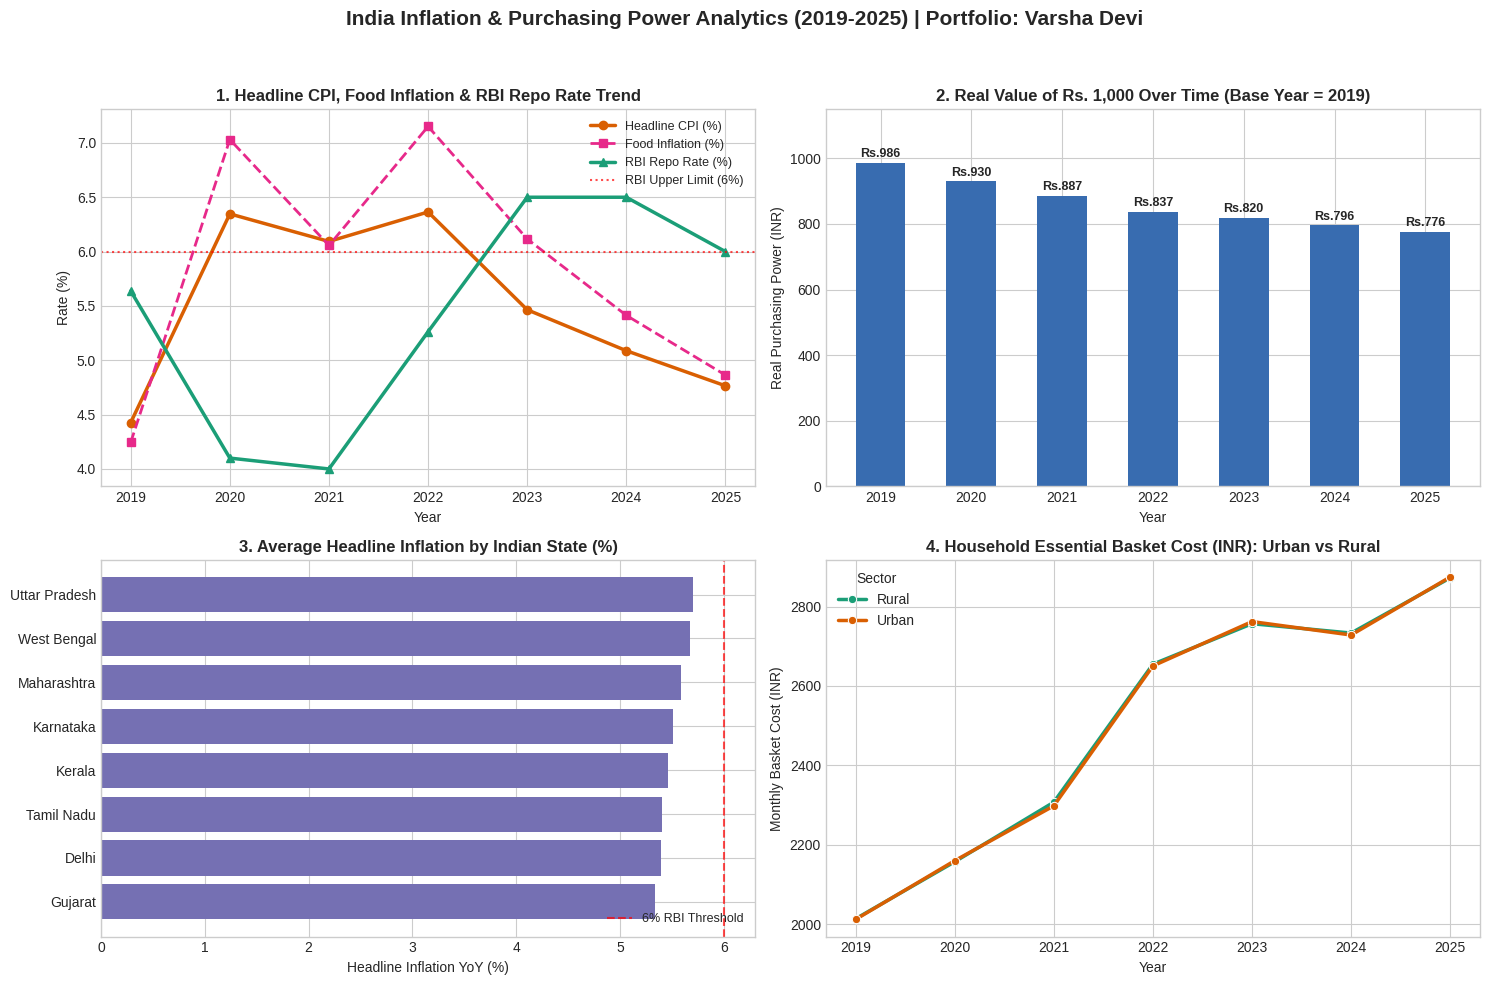

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle("India Inflation & Purchasing Power Analytics (2019-2025) | Portfolio: Varsha Devi", fontsize=15, fontweight='bold', y=0.98)

# Chart 1: Headline Inflation vs RBI Repo Rate
yearly = df_feat.groupby('Year', as_index=False).agg({
    'Headline_Inflation_YoY_Pct': 'mean',
    'Food_Inflation_YoY_Pct': 'mean',
    'RBI_Repo_Rate_Pct': 'mean'
})
ax1 = axes[0, 0]
ax1.plot(yearly['Year'], yearly['Headline_Inflation_YoY_Pct'], marker='o', linewidth=2.5, label='Headline CPI (%)', color='#d95f02')
ax1.plot(yearly['Year'], yearly['Food_Inflation_YoY_Pct'], marker='s', linestyle='--', linewidth=2.0, label='Food Inflation (%)', color='#e7298a')
ax1.plot(yearly['Year'], yearly['RBI_Repo_Rate_Pct'], marker='^', linewidth=2.5, label='RBI Repo Rate (%)', color='#1b9e77')
ax1.axhline(6.0, color='red', linestyle=':', alpha=0.7, label='RBI Upper Limit (6%)')
ax1.set_title("1. Headline CPI, Food Inflation & RBI Repo Rate Trend", fontweight='bold')
ax1.set_xlabel("Year")
ax1.set_ylabel("Rate (%)")
ax1.legend(loc='best', fontsize=9)

# Chart 2: Real Value of Rs. 1,000 Over Time
pp_yearly = df_feat.groupby('Year', as_index=False)['Purchasing_Power_of_1000_INR'].mean()
ax2 = axes[0, 1]
bars = ax2.bar(pp_yearly['Year'].astype(str), pp_yearly['Purchasing_Power_of_1000_INR'], color='#386cb0', width=0.55)
ax2.set_title("2. Real Value of Rs. 1,000 Over Time (Base Year = 2019)", fontweight='bold')
ax2.set_xlabel("Year")
ax2.set_ylabel("Real Purchasing Power (INR)")
ax2.set_ylim(0, 1150)
for bar in bars:
    height = bar.get_height()
    ax2.annotate(f"Rs.{height:.0f}", xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 4), textcoords="offset points", ha='center', fontsize=9, fontweight='bold')

# Chart 3: State-wise Average Inflation
state_avg = df_feat.groupby('State', as_index=False)['Headline_Inflation_YoY_Pct'].mean().sort_values('Headline_Inflation_YoY_Pct')
ax3 = axes[1, 0]
ax3.barh(state_avg['State'], state_avg['Headline_Inflation_YoY_Pct'], color='#7570b3')
ax3.axvline(6.0, color='red', linestyle='--', alpha=0.7, label='6% RBI Threshold')
ax3.set_title("3. Average Headline Inflation by Indian State (%)", fontweight='bold')
ax3.set_xlabel("Headline Inflation YoY (%)")
ax3.legend(loc='lower right', fontsize=9)

# Chart 4: Household Essential Basket Cost (Rural vs Urban)
basket_trend = df_feat.groupby(['Year', 'Sector'], as_index=False)['Monthly_Essential_Basket_INR'].mean()
ax4 = axes[1, 1]
sns.lineplot(data=basket_trend, x='Year', y='Monthly_Essential_Basket_INR', hue='Sector', marker='o', linewidth=2.5, palette=['#1b9e77', '#d95f02'], ax=ax4)
ax4.set_title("4. Household Essential Basket Cost (INR): Urban vs Rural", fontweight='bold')
ax4.set_xlabel("Year")
ax4.set_ylabel("Monthly Basket Cost (INR)")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('eda_summary_chart.png', dpi=150)
plt.show()


In [ ]:
import sqlite3

# Create SQL database in Colab & load the dataset into table 'india_inflation_data'
conn = sqlite3.connect('india_inflation_analytics.db')
df.to_sql('india_inflation_data', conn, if_exists='replace', index=False)

# Example: Run Query 1 (National Annual Inflation & Purchasing Power Erosion)
query_1 = """
SELECT
    Year,
    ROUND(AVG(Headline_Inflation_YoY_Pct), 2) AS Avg_Headline_Inflation_Pct,
    ROUND(AVG(Food_Inflation_YoY_Pct), 2) AS Avg_Food_Inflation_Pct,
    ROUND(AVG(RBI_Repo_Rate_Pct), 2) AS Avg_RBI_Repo_Rate_Pct,
    ROUND(AVG(Purchasing_Power_of_1000_INR), 2) AS Real_Value_of_1000_INR
FROM india_inflation_data
GROUP BY Year
ORDER BY Year ASC;
"""
display(pd.read_sql_query(query_1, conn))


,Year,Avg_Headline_Inflation_Pct,Avg_Food_Inflation_Pct,Avg_RBI_Repo_Rate_Pct,Real_Value_of_1000_INR
0,2019,4.43,4.24,5.64,986.03
1,2020,6.35,7.03,4.10,930.13
2,2021,6.09,6.06,4.00,886.88
3,2022,6.36,7.15,5.26,837.05
4,2023,5.46,6.12,6.50,819.76
5,2024,5.09,5.41,6.50,796.44
6,2025,4.76,4.86,6.00,776.36
